In [1]:

library(sf)
library(ecoSynthesis)
library(dplyr)
library(units)
library(ggplot2)

Linking to GEOS 3.13.0, GDAL 3.8.5, PROJ 9.5.1; sf_use_s2() is TRUE


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


udunits database from /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/library/units/share/udunits/udunits2.xml



In [2]:
here::i_am("synthesis/EFG-map.qmd")
output_dir <- here::here("output-XREFs")
source(here::here("inc/setup.R"))
load(here::here(output_dir, "lookup-tables.rda"))
load(here::here(output_dir, "memb-tables.rda"))

here() starts at /Users/z3529065/proyectos/EIW/TASVEG-XREF



In [3]:
TASVEG_xy <- read_sf(here::here("gisdata","TASVEG_5_0.shp")) |>
    select(VEG_GROUP, VEGCODE, VEGCODE_D)

## Majority rule by expert, unweighted

In [4]:
max_by_expert <- 
    TASVEG_clean |>
    filter(round == 2) |>
    group_by(VEGCODE,expert) |>
    arrange(desc(memb)) |>
    slice(1)

In [5]:
head(max_by_expert)


VEGCODE,EFG,memb,expert,round
<chr>,<chr>,<dbl>,<chr>,<dbl>
AAP,TF1.7,1.0000000,Adelina_Latinovic,2
AAP,TF1.7,0.8000000,David_Keith,2
AAP,TF1.7,1.0000000,Jayne_Balmer,2
AAP,TF1.7,0.9000000,Mark_Tozer,2
AHF,F2.2,0.3333333,Adelina_Latinovic,2
AHF,F2.2,0.5000000,David_Keith,2


In [6]:
EFG_mode_exp_areas <- TASVEG_xy |> 
    mutate(area = st_area(geometry)) |> 
    st_drop_geometry() |>
    left_join(max_by_expert, by = "VEGCODE", relationship = "many-to-many") |> 
    ## group_by(VEG_GROUP, VEGCODE) |>
    group_by(expert, EFG) |>
    summarise(area_total = set_units(sum(area),'km2'), .groups="drop") 
    

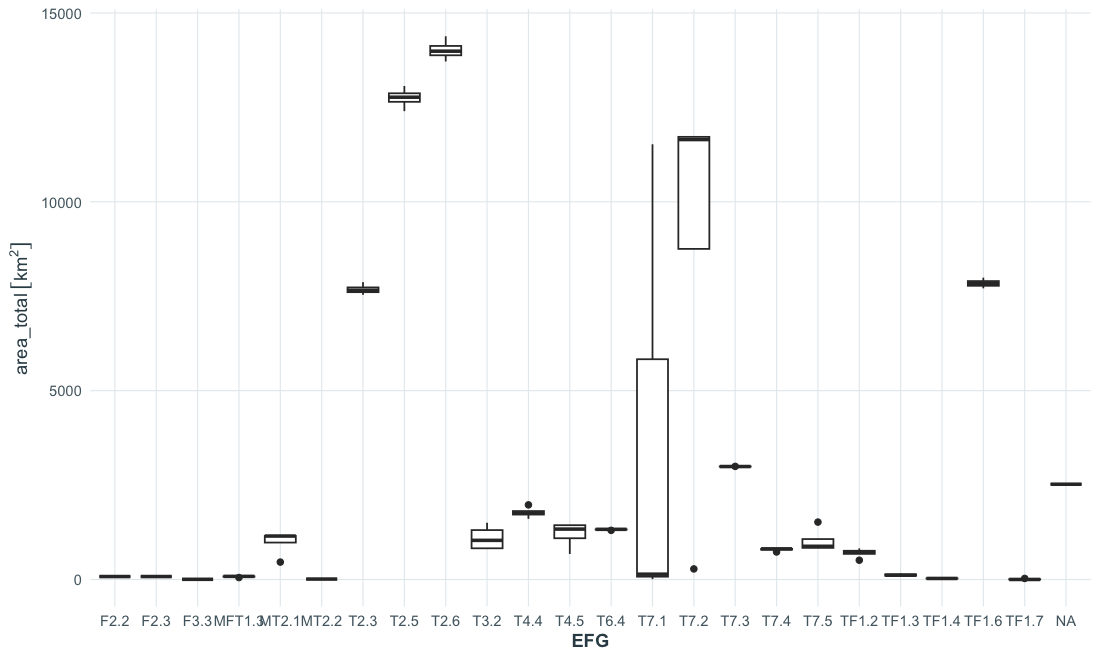

In [7]:
ggplot(EFG_mode_exp_areas, aes(x=EFG, y=area_total)) +
    geom_boxplot() +
  theme_wp3()

## Weighted by membership by expert

In [8]:
memb_by_expert <- 
    TASVEG_clean |>
    filter(round == 2) 

In [9]:
slice(memb_by_expert,1:3)

VEGCODE,EFG,memb,expert,round
<chr>,<chr>,<dbl>,<chr>,<dbl>
AAP,TF1.7,1.0000000,Adelina_Latinovic,2
AHF,F2.2,0.3333333,Adelina_Latinovic,2
AHF,F2.3,0.3333333,Adelina_Latinovic,2


In [10]:
EFG_memb_exp_areas <- TASVEG_xy |> 
    mutate(area = st_area(geometry)) |> 
    st_drop_geometry() |>
    left_join(memb_by_expert, by = "VEGCODE", relationship = "many-to-many") |> 
    ## group_by(VEG_GROUP, VEGCODE) |>
    group_by(expert, EFG) |>
    summarise(area_total = set_units(sum(area * memb),'km2') , .groups="drop") 

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”


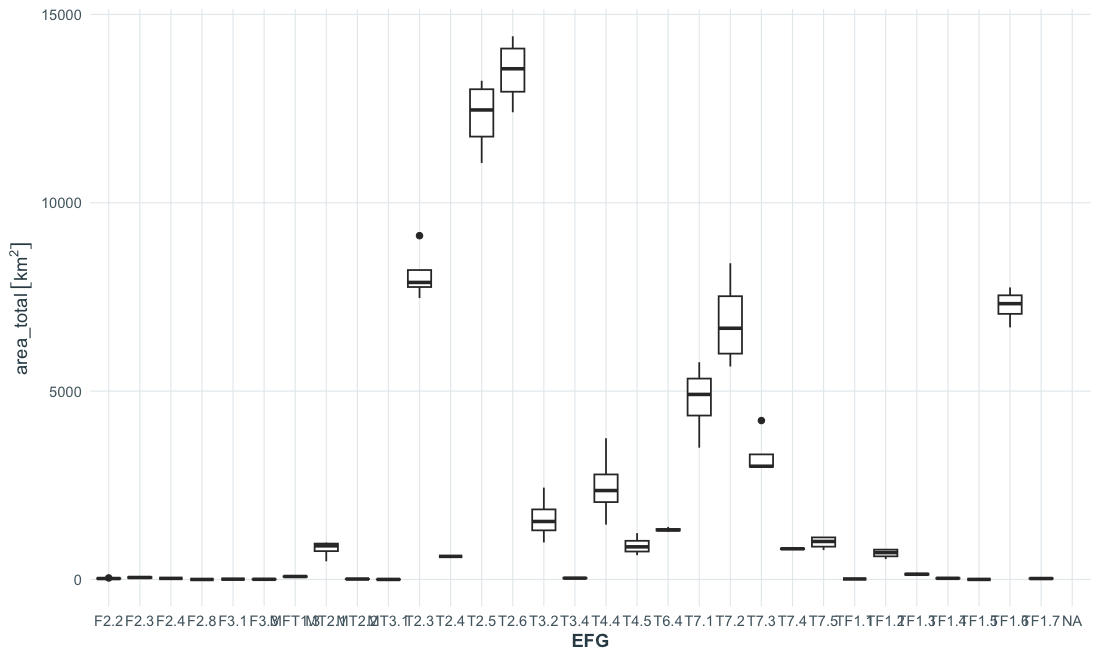

In [11]:
ggplot(EFG_memb_exp_areas, aes(x=EFG, y=area_total)) +
    geom_boxplot() +
  theme_wp3()

In [12]:
memb_by_efg <- 
    TASVEG_clean |>
    filter(round == 2) |>
    group_by(VEGCODE) |>
    mutate(total_memb=sum(memb)) |>
    ungroup() |>
    group_by(VEGCODE, EFG) |>
    summarise(prop=sum(memb/total_memb), .groups = "drop")

In [13]:
head(memb_by_efg)

VEGCODE,EFG,prop
<chr>,<chr>,<dbl>
AAP,F2.8,0.0500000
AAP,TF1.6,0.0250000
AAP,TF1.7,0.9250000
AHF,F2.2,0.3458333
AHF,F2.3,0.3833333
AHF,F2.4,0.0750000


In [14]:
EFG_agg_areas <- TASVEG_xy |> 
    mutate(area = st_area(geometry)) |> 
    st_drop_geometry() |>
    left_join(memb_by_efg, by = "VEGCODE", relationship = "many-to-many") |> 
    ## group_by(VEG_GROUP, VEGCODE) |>
    group_by(EFG) |>
    summarise(area_total = set_units(sum(area * prop),'km2') , .groups="drop") 

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


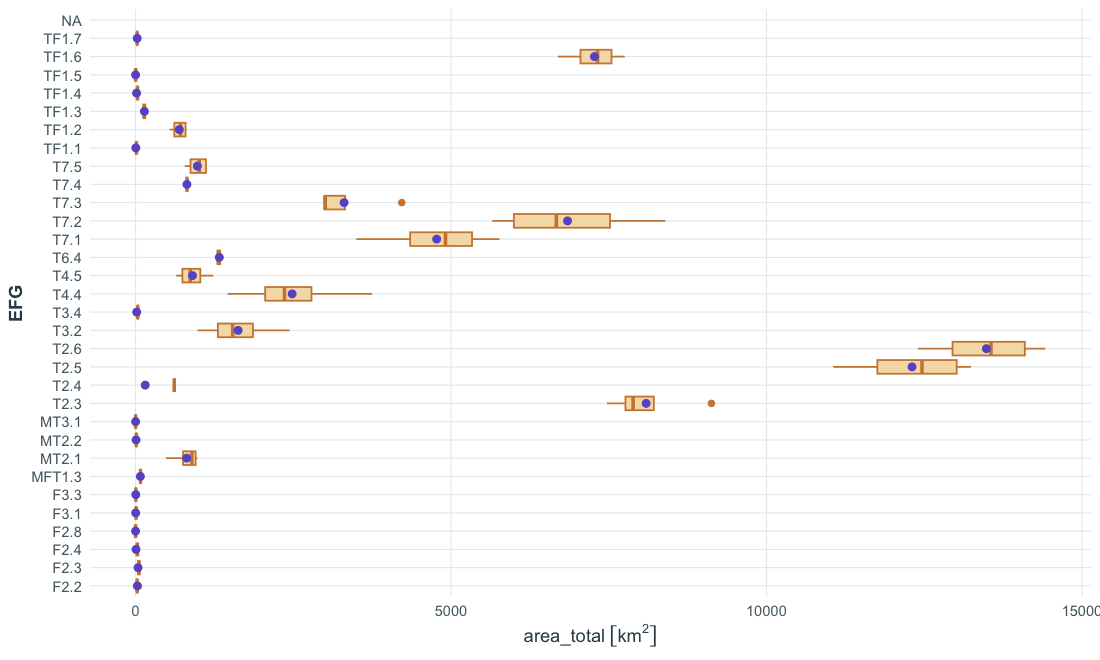

In [51]:
ggplot() +
    geom_boxplot(data=EFG_memb_exp_areas, aes(y=EFG, x=area_total), fill="wheat", col="peru") +
  geom_point(data=EFG_agg_areas, aes(y=EFG, x=area_total), col="slateblue3", size=2) +
  theme_wp3()

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


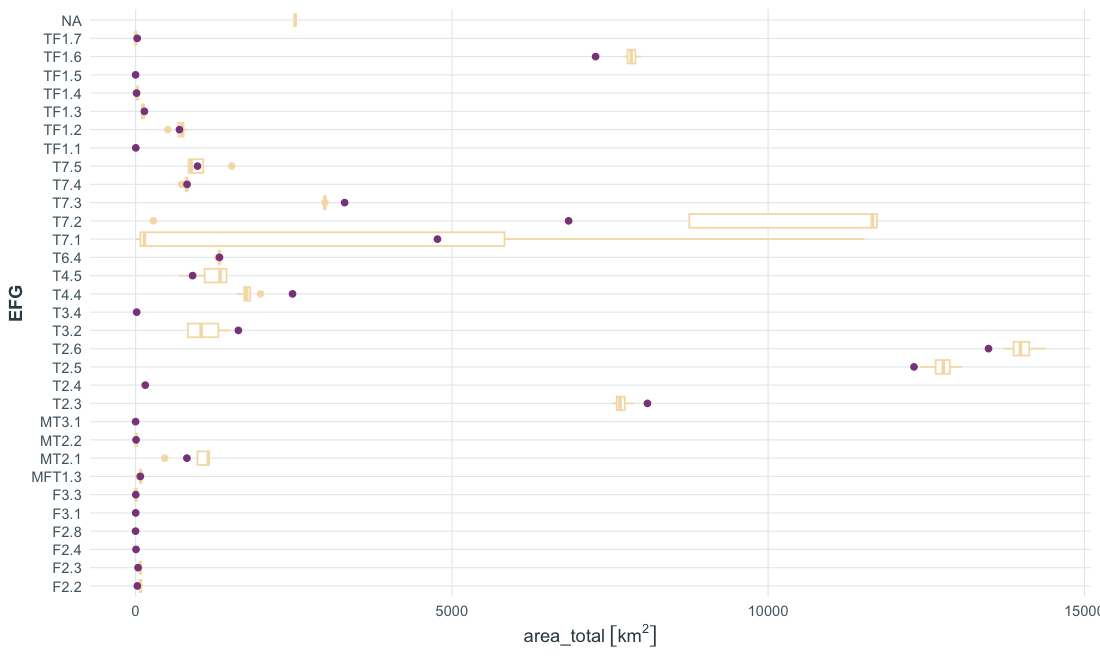

In [45]:
ggplot() +
  geom_boxplot(data=EFG_mode_exp_areas, aes(y=EFG, x=area_total), col="wheat") +
  geom_point(data=EFG_agg_areas, aes(y=EFG, x=area_total), col="orchid4") +
  theme_wp3()

In [32]:
max_prop_by_efg <- memb_by_efg |> 
    group_by(VEGCODE) |>
    arrange(desc(prop)) |>
    slice(1) |>
    ungroup() |>
    arrange(desc(prop))

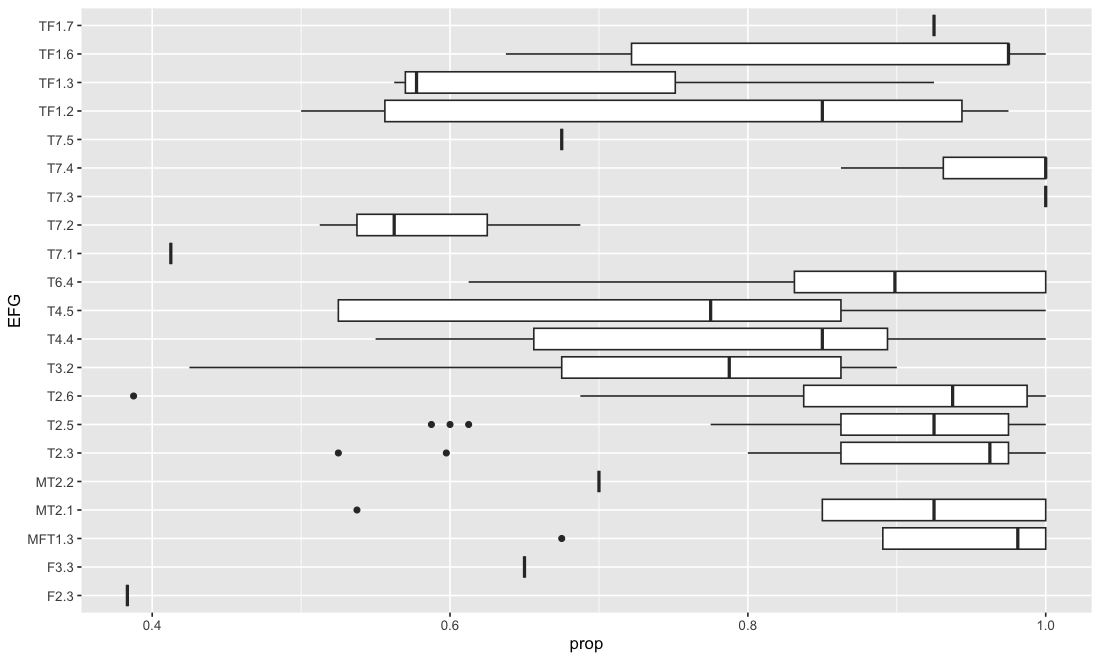

In [36]:
ggplot(max_prop_by_efg) +
    geom_boxplot(aes(y=EFG,x=prop))

In [42]:
#TASVEG_clean |>
#    filter(round == 2)
max_prop_by_efg |> summarise(n_distinct(EFG))

n_distinct(EFG)
<int>
21
